# ROI_processing

In [3]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData

import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns

import hotspot

In [ ]:
# Technology 1: Xenium
sdata = sd.read_zarr("/media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed_with_scores.zarr")#"/media/sergio/Meninges/troutpy/rois/xenium_mscolon_5k/data_processed_filtered.zarr")
saving_path='/media/sergio/Meninges/troutpy/figures'

# Module analysis

In [6]:
adata = sdata["table"]


In [1]:
# v1

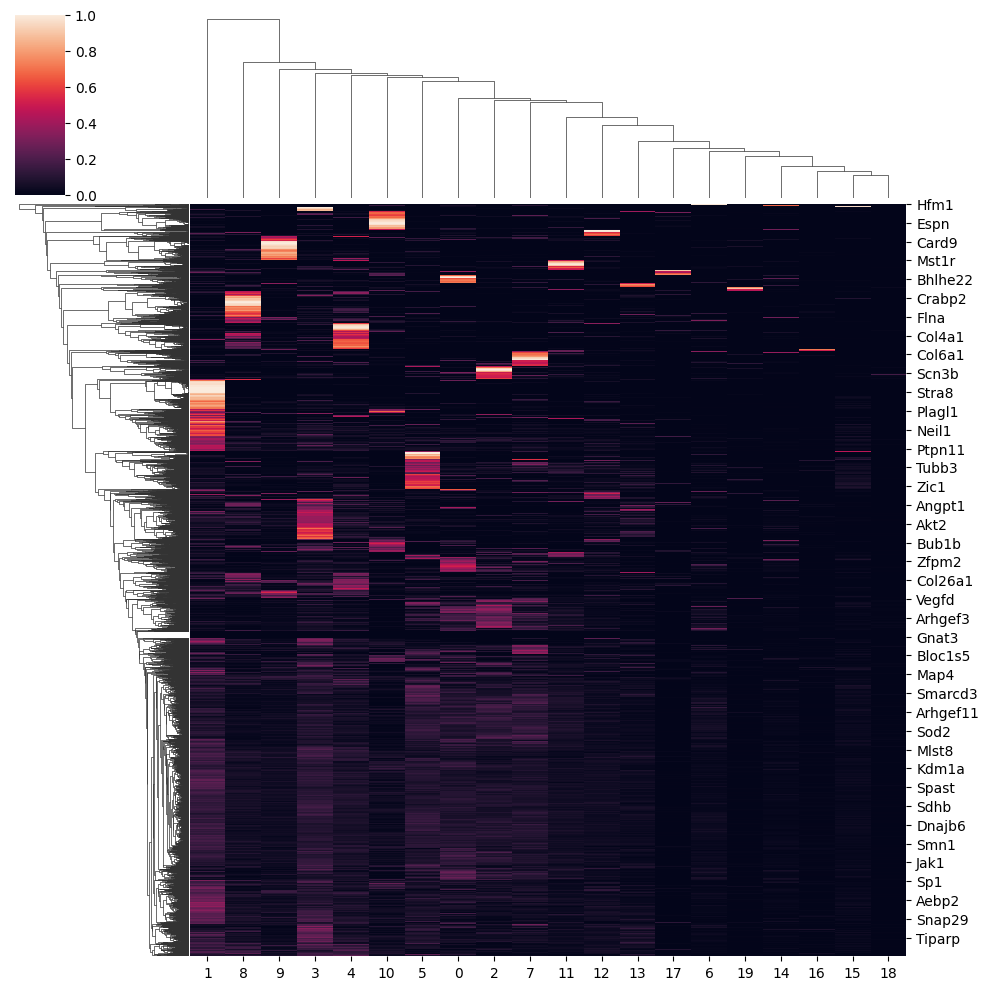

In [87]:
sns.clustermap(contrib_norm.fillna(0))

In [112]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Load data
expr = sdata['table'].to_df()  # intracellular expression: cells × genes
sdata['table'].X=sdata['table'].layers['raw'].todense()
cell_types = sdata['table'].obs['leiden']  # cell type annotations

xrna_count = sdata['xrna_metadata'].var['count']  # total uRNA counts per gene
contrib_df = sdata['source_score'].to_df()  # transcripts × cell_types (source scores)
contrib_df['gene'] = sdata['source_score'].obs['gene']

# 2. Normalize source scores to get contribution per gene per cell type
contrib_matrix = contrib_df.groupby('gene').sum()
contrib_norm = contrib_matrix.div(contrib_matrix.sum(axis=1), axis=0)

# 3. Align and compute estimated extracellular transcript counts per cell type
genes_common = contrib_norm.index.intersection(xrna_count.index)
xrna_count = xrna_count.loc[genes_common]
contrib_norm = contrib_norm.loc[genes_common]
extra_count_matrix = contrib_norm.mul(xrna_count, axis=0)  # genes × cell_types

# 4. Compute intracellular transcript counts per cell type
intra_count_matrix = expr.groupby(cell_types).sum().T  # genes × cell_types
intra_count_mean = expr.groupby(cell_types).mean().T  # genes × cell_types

# Align genes and cell types
genes_final = extra_count_matrix.index.intersection(intra_count_matrix.index)
celltypes_final = extra_count_matrix.columns.intersection(intra_count_matrix.columns)
extra_count_matrix = extra_count_matrix.loc[genes_final, celltypes_final]
intra_count_matrix = intra_count_matrix.loc[genes_final, celltypes_final]
intra_count_mean = intra_count_mean.loc[genes_final, celltypes_final]


# 5. Compute log2(extracellular / intracellular) per gene per cell type
pseudo = 1  # to avoid division by zero
log_ratio = np.log2((extra_count_matrix + pseudo) / (intra_count_matrix + pseudo))



In [93]:
dict_anno={0:'DG',1:'Oligodendrocytes',2:'CA1-2',3:'Astrocytes',4:'Endothelial',5:'EXC neurons Thal.',6:'CA3',7:'EXC. neurons CTX',8:'SMC/Pericytes',
9:'Microglia',10:'Ependymal cells',11:'INH neurons',12:'OPC',13:'Astrocytes',14:'SGZ Neuroblasts',15:'Oligodendrocytes',16:'Cajal-Retzius',17:'Choroid plexus',
18:'Astrocytes',19:'INH neurons CP'}
log_ratio.columns=log_ratio.columns.astype(int).map(dict_anno)

In [94]:
#extra_count_matrix.columns=extra_count_matrix.columns.astype(int).map(dict_anno)
#intra_count_matrix.columns=intra_count_matrix.columns.astype(int).map(dict_anno)

In [46]:
# 6. Plot heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(log_ratio.T, cmap='coolwarm', center=0, xticklabels=True, yticklabels=True)
plt.title("log2(Extracellular / Intracellular) Transcript Enrichment")
plt.xlabel("Gene")
plt.ylabel("Cell Type")
plt.tight_layout()
plt.show()


KeyboardInterrupt: 

Error in callback <function flush_figures at 0x7f2342615cf0> (for post_execute), with arguments args (),kwargs {}:


KeyboardInterrupt: 

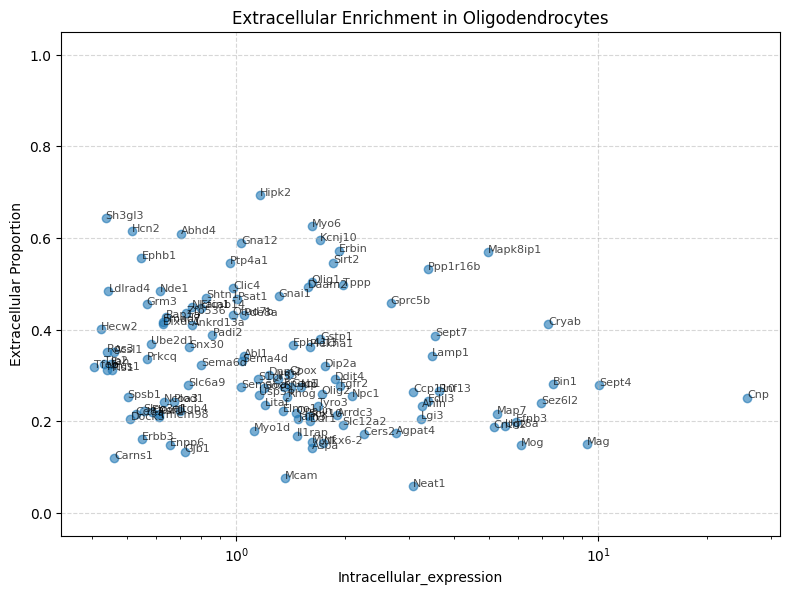

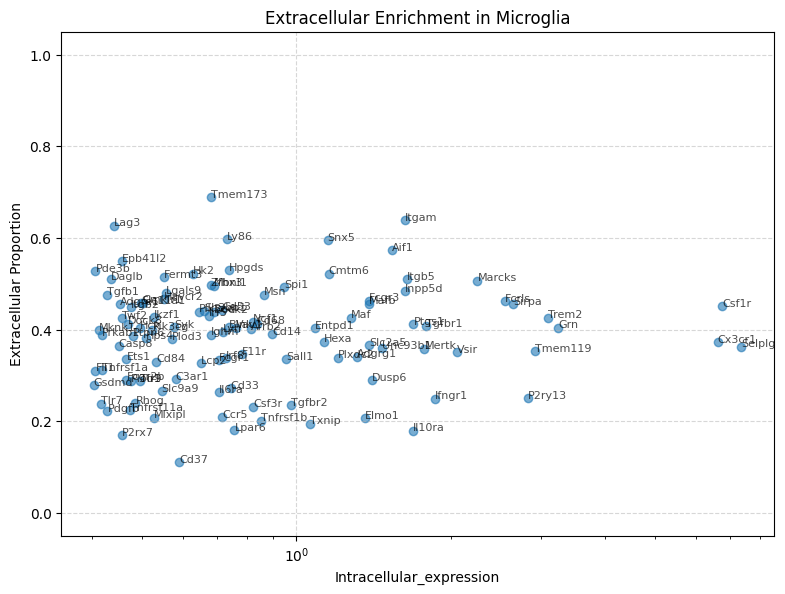

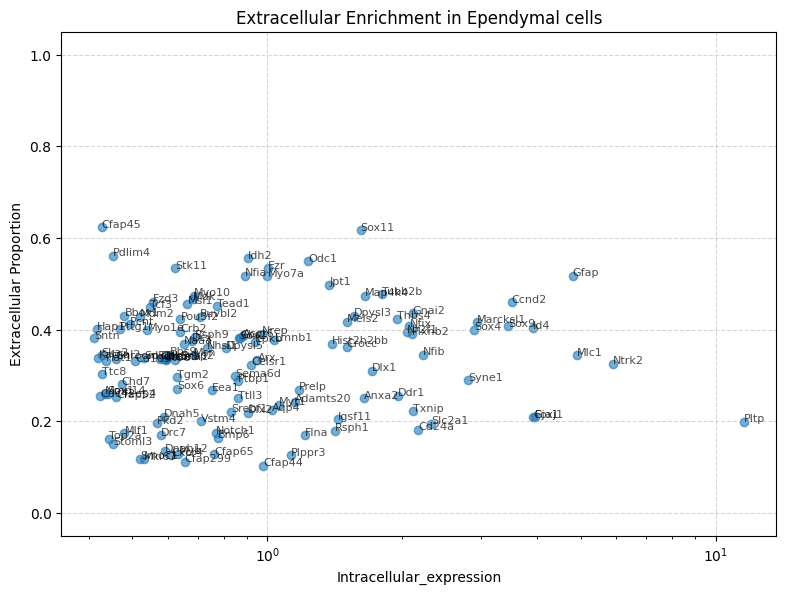

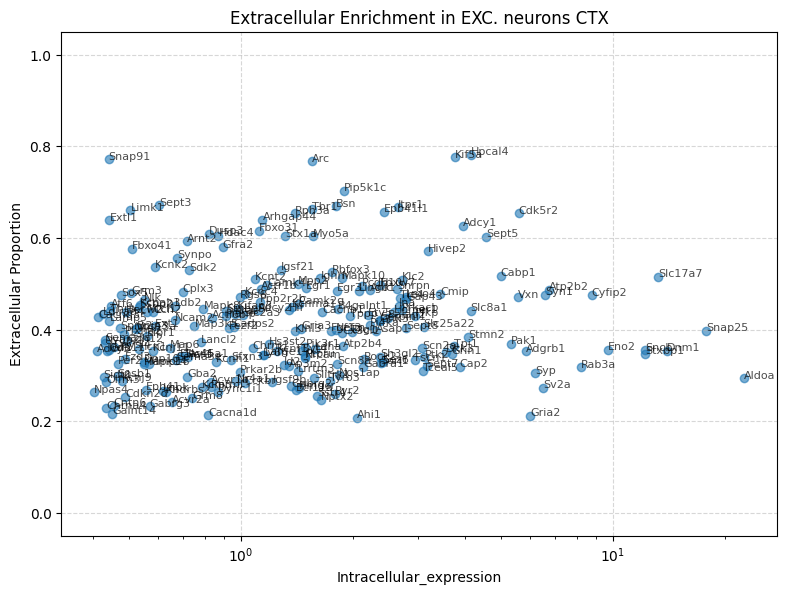

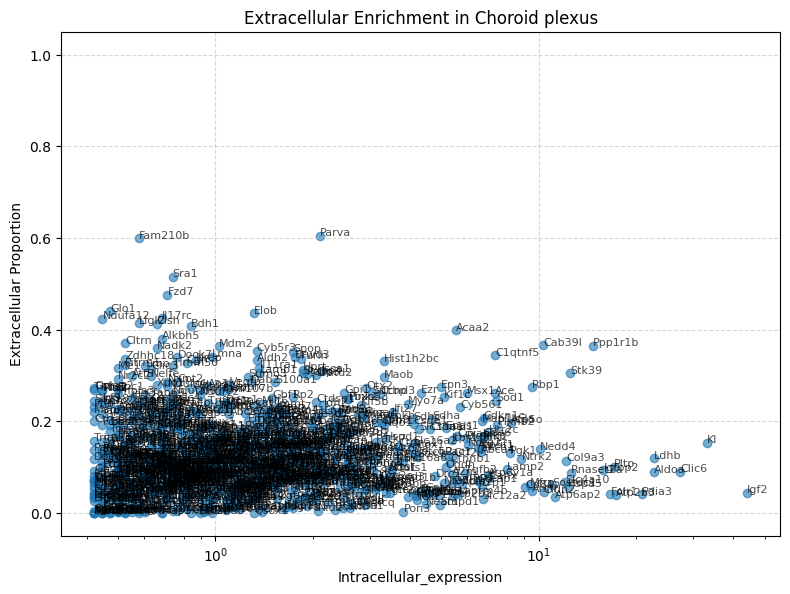

...

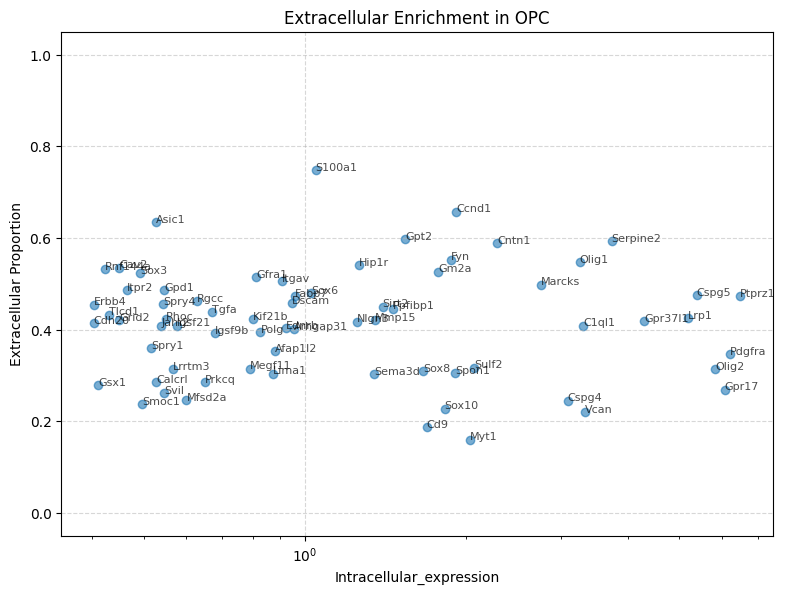

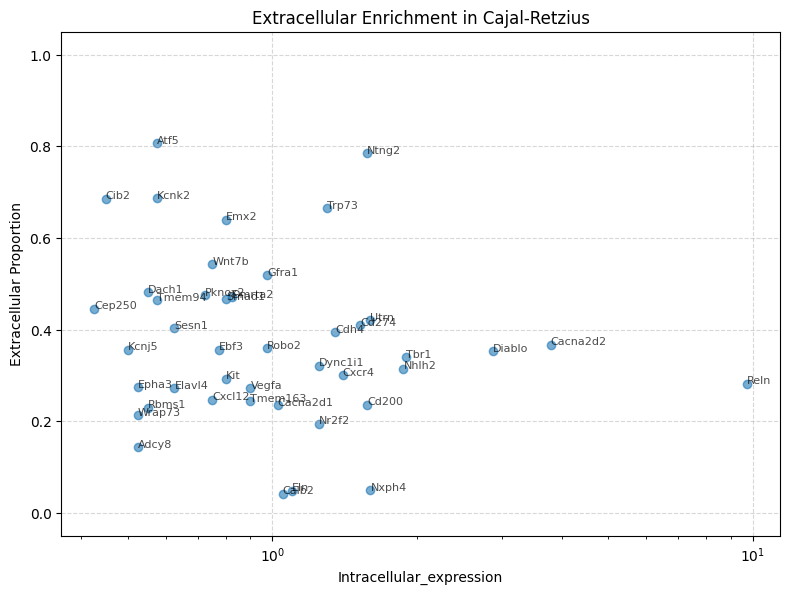

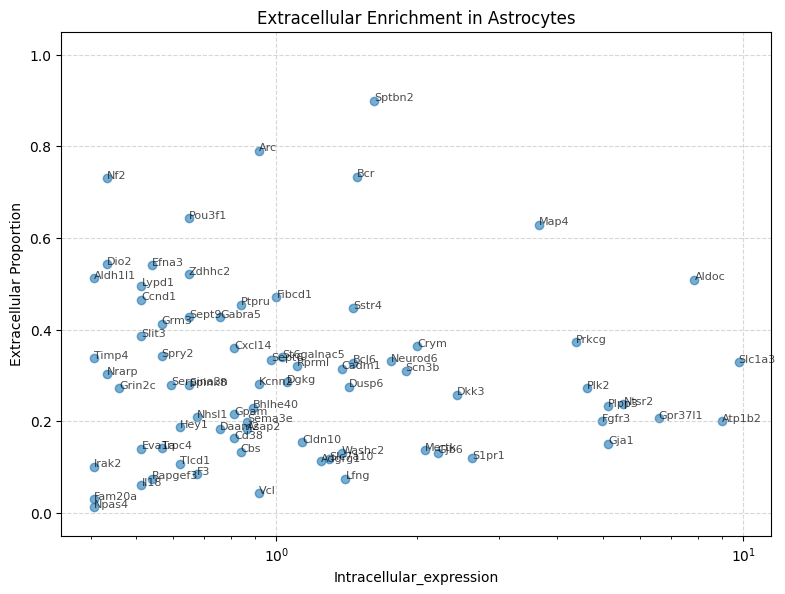

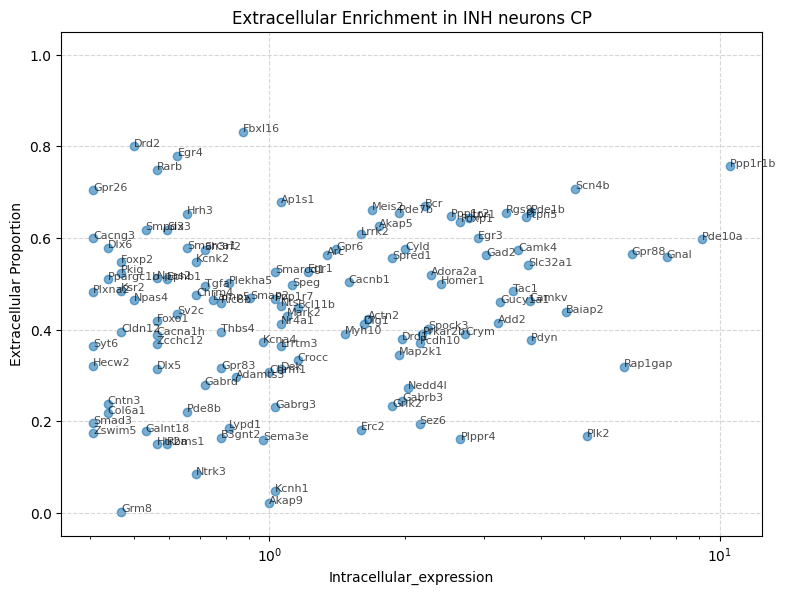

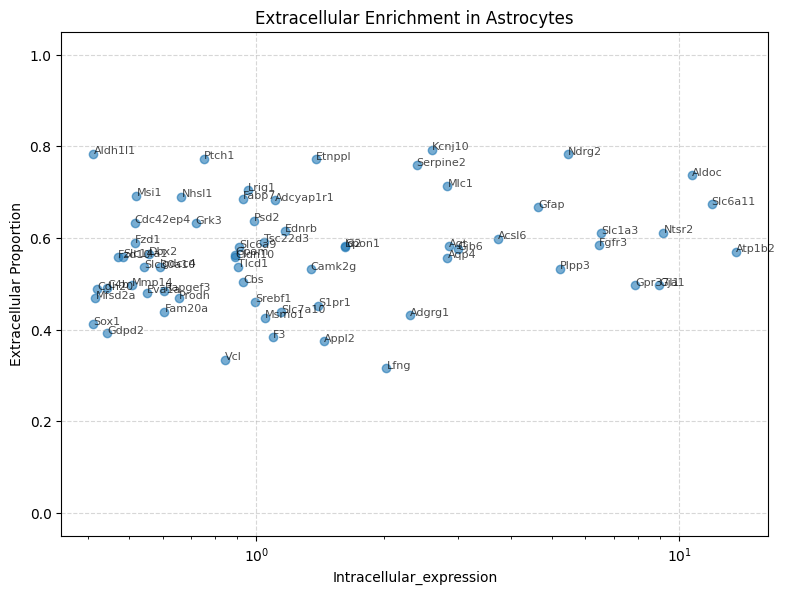

In [194]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Make sure extra_count_matrix and intra_count_matrix are aligned
assert extra_count_matrix.shape == intra_count_matrix.shape
assert all(extra_count_matrix.index == intra_count_matrix.index)
assert all(extra_count_matrix.columns == intra_count_matrix.columns)

# Compute extracellular proportion: extra / (extra + intra)
total_counts = extra_count_matrix + intra_count_matrix
extracellular_proportion = extra_count_matrix / total_counts

# The gene needs to represent at least 1% of the total transcripts detected intracellularly
filtering_criteria = intra_count_mean.div(intra_count_mean.sum(axis=1), axis=0) > 0.1
filtering_counts = intra_count_mean > 0.4
combined = filtering_counts & filtering_criteria

# Collect results here
filtered_data = []

# Prepare data for scatter plots and collect filtered gene info
for cell_type in extra_count_matrix.columns:
    extra = extra_count_matrix[cell_type]
    intra = intra_count_matrix[cell_type]
    intra_mean = intra_count_mean[cell_type]
    filt = combined[cell_type]
    prop = extracellular_proportion[cell_type]

    # Apply filters
    extra = extra[filt]
    intra_mean = intra_mean[filt]
    prop = prop[filt].fillna(0)

    # Store the filtered data
    for gene in extra.index:
        filtered_data.append({
            'gene': gene,
            'cell_type': dict_anno[int(cell_type)],
            'extracellular_proportion': prop[gene]
        })

    # Optional: keep the scatter plot
    plt.figure(figsize=(8, 6))
    plt.scatter(intra_mean, prop, alpha=0.6)

    for gene, x, y in zip(extra.index, intra_mean, prop):
        plt.text(x, y, gene, fontsize=8, alpha=0.7)

    plt.xlabel("Intracellular_expression")
    plt.ylabel("Extracellular Proportion")
    plt.title(f"Extracellular Enrichment in {dict_anno[int(cell_type)]}")
    plt.ylim(-0.05, 1.05)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.xscale('log')
    plt.show()

# Create final dataframe
filtered_df = pd.DataFrame(filtered_data)


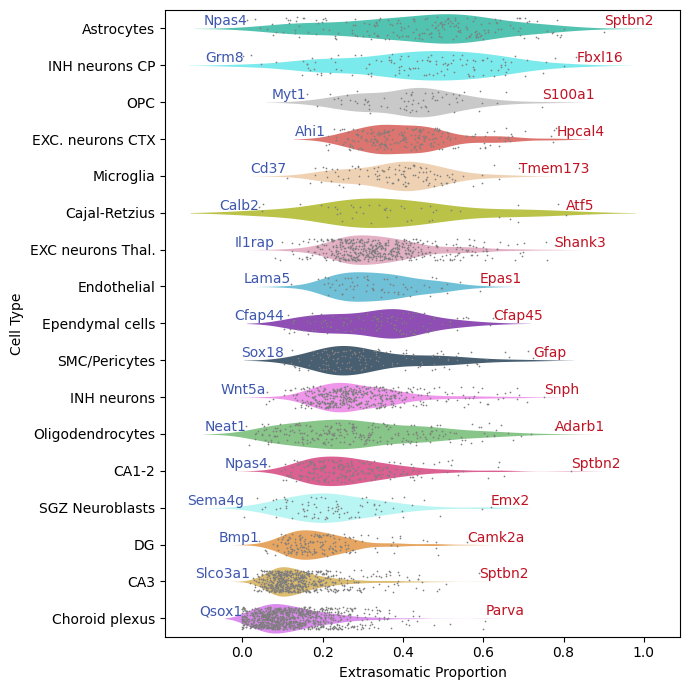

In [308]:
order_ct=filtered_df.loc[:,['cell_type','extracellular_proportion']].groupby('cell_type').mean().sort_values(by='extracellular_proportion',ascending=False).index
cols=[coldict[c] for c in order_ct]
import matplotlib.pyplot as plt
import seaborn as sns

# Parameters
n = 1  # number of top/bottom genes to label per cell type

# Create the plot
plt.figure(figsize=(7, 7), dpi=100)

ax = sns.violinplot(
    data=filtered_df,
    y='cell_type',
    x='extracellular_proportion',
    order=order_ct,alpha=0.8,linewidth=0,
    palette=cols,
    inner=None
)

sns.stripplot(
    data=filtered_df,
    y='cell_type',
    x='extracellular_proportion',
    color='gray',
    s=1.2,
    order=order_ct,
    jitter=0.3,
    linewidth=0.01,
    ax=ax
)

# Annotate top and bottom n genes for each cell type
for cell_type in order_ct:
    df_sub = filtered_df[filtered_df['cell_type'] == cell_type]

    # Top n
    top_n = df_sub.nlargest(n, 'extracellular_proportion')
    for _, row in top_n.iterrows():
        ax.text(
            row['extracellular_proportion'], cell_type,
            row['gene'],
            color='#bf1324', fontsize=10, va='bottom', ha='left'
        )

    # Bottom n
    bottom_n = df_sub.nsmallest(n, 'extracellular_proportion')
    for _, row in bottom_n.iterrows():
        ax.text(
            row['extracellular_proportion'], cell_type,
            row['gene'],
            color='#3d57ad', fontsize=10, va='bottom', ha='right'
        )

plt.xlabel('Extrasomatic Proportion')
plt.ylabel('Cell Type')
plt.tight_layout()
plt.savefig
plt.savefig(os.path.join(saving_path,'cells_extromatic_proportion.pdf'))
plt.show()

In [193]:
extracellular_proportion

,1,9,10,7,17,6,5,2,11,0,8,14,15,4,3,12,16,18,19,13
A2m,0.353727,0.162866,0.323869,0.000151,0.085175,0.000458,0.168504,1.532863e-02,0.001000,0.000051,0.439836,0.000746,NaN,0.345582,0.291491,0.401370,0.176364,NaN,NaN,0.323462
Aatf,0.321014,0.339532,0.186646,0.209627,0.049180,0.043518,0.163618,7.203753e-02,0.076356,0.040990,0.192515,0.022989,0.118336,0.366164,0.265288,0.182084,0.338759,0.565828,1.527945e-02,0.240787
Abca1,0.298813,0.403380,0.295367,0.103153,0.074527,0.126037,0.267648,9.290860e-02,0.176220,0.076234,0.354702,0.172201,0.273739,0.459263,0.396511,0.329487,0.397430,0.210962,NaN,0.521159
Abca13,NaN,NaN,0.000078,NaN,NaN,NaN,NaN,2.297270e-07,NaN,0.968421,0.000088,NaN,NaN,NaN,0.232919,0.028802,NaN,NaN,NaN,NaN
Abca3,0.296571,0.281503,0.167406,0.251907,0.061200,0.059272,0.221953,8.973505e-02,0.179339,0.080621,0.348142,0.227534,0.233868,0.385793,0.371307,0.336933,0.296157,0.176044,1.940864e-01,0.409110
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Zswim5,0.421745,0.403869,0.055173,0.206107,0.297273,0.080442,0.202811,2.124386e-01,0.188853,0.183975,0.106624,0.278900,0.143393,0.404766,0.645862,0.436891,0.575280,0.038931,1.737631e-01,0.500957
Zswim9,0.711301,0.309133,0.469709,0.452800,0.381876,0.079097,0.471727,1.645297e-01,0.291046,0.141679,0.515920,0.220125,0.288246,0.770907,0.699675,0.413179,0.017172,NaN,5.589151e-02,0.754102
Zup1,0.102913,0.384957,0.000002,0.171209,0.000008,0.018070,0.090377,5.964000e-02,0.064311,0.027484,0.152937,0.129530,0.077573,0.475495,0.237717,0.448541,0.000128,0.018854,3.164779e-09,0.222765
Zyx,0.455288,0.576524,0.223856,0.433625,0.071786,0.165501,0.432380,2.761585e-02,0.307044,0.149898,0.472381,0.289711,0.491312,0.612602,0.524219,0.506325,0.630102,0.053879,1.217913e-03,0.440042


# Conservative approach

In [171]:
import pandas as pd
import numpy as np
from anndata import AnnData

def identify_unique_expression(
    adata: AnnData,
    threshold: float = 0.2,
    min_mean: float = 1.0
) -> pd.DataFrame:
    """
    Determine for each gene whether it is uniquely expressed in one cell type or multiple,
    based on mean expression per cell type.

    A gene is considered expressed in a cell type if:
    - The mean expression in that cell type contributes more than `threshold`
      of the total mean across all cell types, AND
    - The mean expression is above `min_mean` in that cell type.

    Parameters
    ----------
    adata : AnnData
        AnnData object with expression data in .X and cell type annotations in .obs['cell_type'].
    threshold : float
        Minimum fraction of total mean expression the cell type must contribute to be considered expressed.
    min_mean : float
        Minimum mean expression value in the cell type for a gene to be considered expressed.

    Returns
    -------
    pd.DataFrame
        DataFrame with gene names as index and two columns:
        - 'expression_pattern': 'unique' or 'multiple'
        - 'unique_cell_type': cell type name if uniquely expressed, else None
    """
    cell_types = adata.obs['cell_type'].astype(str)
    gene_names = adata.var_names
    result = []

    # Convert to dense matrix if sparse
    X = adata.X.toarray() if hasattr(adata.X, 'toarray') else adata.X

    # Create map of cell type -> integer indices
    cell_type_groups = cell_types.groupby(cell_types).groups
    cell_indexer = pd.Series(np.arange(adata.n_obs), index=adata.obs.index)

    for gene_idx, gene in enumerate(gene_names):
        mean_expr_by_ct = {}
        for ct, labels in cell_type_groups.items():
            int_indices = cell_indexer.loc[labels].values
            mean_expr_by_ct[ct] = X[int_indices, gene_idx].mean()

        total_mean = sum(mean_expr_by_ct.values())
        if total_mean == 0:
            result.append({'expression_pattern': 'multiple', 'unique_cell_type': None})
            continue

        expressed_in = []
        for ct, mean_expr in mean_expr_by_ct.items():
            frac = mean_expr / total_mean
            if frac >= threshold and mean_expr >= min_mean:
                expressed_in.append(ct)

        if len(expressed_in) == 1:
            result.append({'expression_pattern': 'unique', 'unique_cell_type': expressed_in[0]})
        else:
            result.append({'expression_pattern': 'multiple', 'unique_cell_type': None})

    return pd.DataFrame(result, index=gene_names)


In [296]:
result_table = identify_unique_expression(adata,threshold=0.9, min_mean = 0.5)
unique_expression_genes=result_table[result_table['expression_pattern']!='multiple']
adata_cell_type_specific=adata[:,unique_expression_genes.index]

In [297]:
merged = pd.merge(unique_expression_genes,sdata['xrna_metadata'].var,left_index=True,right_index=True, how='inner')


In [298]:
sdata['table'].uns['cell_type_colors'] = [
    "#0FCCAC",   # Aqua Teal – bright and fresh, great for highlighting
    "#ED2073",   # Vivid Magenta Pink – strong contrast, eye-catching
    "#ebb434", 
    "#BFCE00",   # Chartreuse Green – light, acidic green, good for uncommon categories
    "#DF5AFF",   # Electric Purple – vibrant, stands out, ideal for rare cell types
    "#FC911D",   # Vivid Orange – warm and bold, useful for attention-grabbing
    "#E891B4",   # Pastel Rose – soft and gentle, good for subtle categories
    "#eb3d34",   # Mint Cream – pale green, useful for background or low-contrast layers
    "#37BEE2",   # Bright Sky Blue – vibrant and energetic, visually accessible
    "#790DB7",   # Royal Purple – deep and rich, contrasts well with yellows and greens
    "#ff69f7",   # Lime Green – bold but not neon, works well for active states
    "#43FBFF",   # Neon Cyan – very bright, best with dark backgrounds
    "#F7C894",   # Peach – soft and neutral, ideal for subtle cell states
    "#BCBCBC",   # Medium Gray – neutral, useful as a baseline or control color
    "#5cc460",   # Charcoal – strong neutral, works well for text or background
    "#9CFFFC",
    "#123755",   # Deep Navy Blue – dark and cool, good background or strong category
    "#FFFF7B",   # Soft Lemon Yellow – light and readable on dark backgrounds
]

In [299]:
order_ct=merged.loc[:,['unique_cell_type','extracellular_proportion']].groupby('unique_cell_type').mean().sort_values(by='extracellular_proportion',ascending=False).index

In [300]:
coldict=dict(zip(np.unique(sdata['table'].obs['cell_type']),sdata['table'].uns['cell_type_colors']))
cols=[coldict[c] for c in order_ct]

In [301]:
merged

,expression_pattern,unique_cell_type,count,logfoldratio_over_noise,control_probe,p_value_Poisson,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh,in_out_spearmanR,in_out_pvalue,proportion_of_colocalized
Abca4,unique,Choroid plexus,60.0,2.302585,False,0.000000e+00,0.893993,0.106007,1.101746,0.018048,3.088640e-13,0.000006,NaN,-0.001040,9.205842e-01,0.000000
Ace,unique,Choroid plexus,156.0,3.258097,False,0.000000e+00,0.832797,0.167203,0.575138,0.023147,0.000000e+00,0.000006,NaN,0.160829,2.851144e-54,0.026316
Cldn1,unique,Choroid plexus,41.0,1.921813,False,0.000000e+00,0.866013,0.133987,0.835712,-0.001334,3.023508e-01,0.000006,NaN,0.131799,7.158262e-37,0.025000
Cldn2,unique,Choroid plexus,21.0,1.252763,False,0.000000e+00,0.967239,0.032761,2.354751,0.055933,0.000000e+00,0.000006,NaN,0.073431,1.840394e-12,0.050000
Clic3,unique,Choroid plexus,32.0,1.673976,False,0.000000e+00,0.750000,0.250000,0.068166,-0.001047,3.432421e-01,0.000006,NaN,-0.003870,7.107276e-01,0.032258
Clic6,unique,Choroid plexus,169.0,3.338139,False,0.000000e+00,0.906475,0.093525,1.240886,0.279027,0.000000e+00,0.000006,NaN,0.419965,0.000000e+00,0.206349
Cltrn,unique,Choroid plexus,25.0,1.427116,False,0.000000e+00,0.845679,0.154321,0.670659,-0.000781,3.829852e-01,0.000006,NaN,0.022190,3.344801e-02,0.041667
Crhbp,unique,INH neurons,542.0,4.503507,False,0.000000e+00,0.737911,0.262089,0.004693,0.107305,0.000000e+00,0.000006,NaN,0.181200,1.229996e-68,0.195652
Dnah12,unique,Ependymal cells,28.0,1.540445,False,0.000000e+00,0.909677,0.090323,1.279256,-0.000920,3.620525e-01,0.000006,NaN,0.138486,1.452987e-40,0.000000
Ebf3,unique,Cajal-Retzius,24.0,1.386294,False,0.000000e+00,0.856287,0.143713,0.754345,-0.000810,3.785428e-01,0.000006,NaN,0.031131,2.846244e-03,0.000000


In [302]:
merged_labelled.sort_values(by='count')

,expression_pattern,unique_cell_type,count,logfoldratio_over_noise,control_probe,p_value_Poisson,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh,in_out_spearmanR,in_out_pvalue,proportion_of_colocalized,gene_name
Slc16a8,unique,Choroid plexus,20.0,1.203973,False,0.0,0.929577,0.070423,1.549771,-0.000551,4.184203e-01,0.000006,NaN,0.155347,1.035666e-50,0.111111,Slc16a8
Cldn2,unique,Choroid plexus,21.0,1.252763,False,0.0,0.967239,0.032761,2.354751,0.055933,0.000000e+00,0.000006,NaN,0.073431,1.840394e-12,0.050000,Cldn2
Mfrp,unique,Choroid plexus,26.0,1.466337,False,0.0,0.958926,0.041074,2.119986,0.006291,5.915065e-03,0.000006,NaN,0.270035,3.232373e-153,0.040000,Mfrp
Clic3,unique,Choroid plexus,32.0,1.673976,False,0.0,0.750000,0.250000,0.068166,-0.001047,3.432421e-01,0.000006,NaN,-0.003870,7.107276e-01,0.032258,Clic3
Nts,unique,INH neurons CP,33.0,1.704748,False,0.0,0.810345,0.189655,0.421806,0.020136,4.440892e-16,0.000006,NaN,0.155700,6.156367e-51,0.000000,Nts
Steap1,unique,Choroid plexus,35.0,1.763589,False,0.0,0.926625,0.073375,1.505516,0.018834,2.975398e-14,0.000006,NaN,0.011373,2.757745e-01,0.000000,Steap1
Cldn1,unique,Choroid plexus,41.0,1.921813,False,0.0,0.866013,0.133987,0.835712,-0.001334,3.023508e-01,0.000006,NaN,0.131799,7.158262e-37,0.025000,Cldn1
Sostdc1,unique,Choroid plexus,42.0,1.945910,False,0.0,0.950237,0.049763,1.918993,0.028202,0.000000e+00,0.000006,NaN,0.247798,1.452486e-128,0.024390,Sostdc1
Folr1,unique,Choroid plexus,51.0,2.140066,False,0.0,0.954626,0.045374,2.015942,0.030410,0.000000e+00,0.000006,NaN,0.318509,1.289186e-215,0.020833,Folr1
Abca4,unique,Choroid plexus,60.0,2.302585,False,0.0,0.893993,0.106007,1.101746,0.018048,3.088640e-13,0.000006,NaN,-0.001040,9.205842e-01,0.000000,Abca4


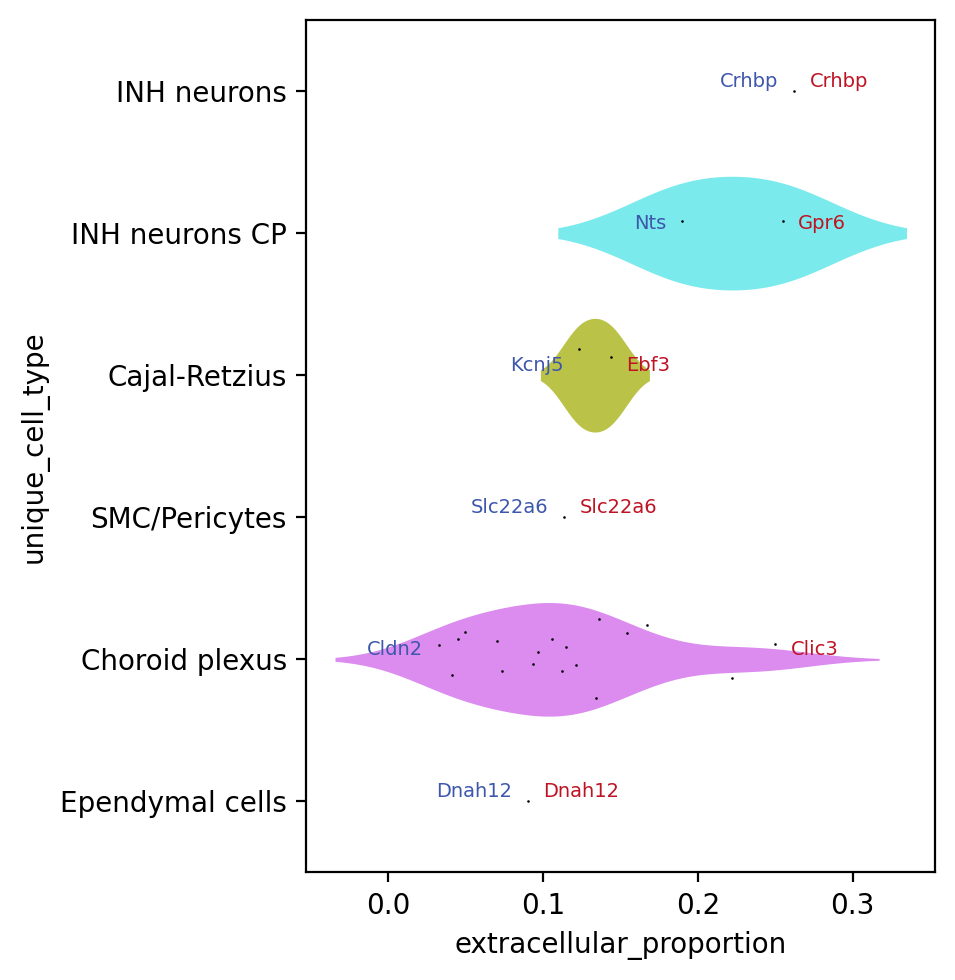

In [303]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Parameters
m = 1
n = 1

# Prepare data
merged_labelled = merged.copy()
merged_labelled['gene_name'] = merged_labelled.index

# Create safe order_ct lookup
y_map = {ct: i for i, ct in enumerate(order_ct)}

# Filter to only valid cell types
valid_ct = [ct for ct in merged_labelled['unique_cell_type'].unique() if ct in order_ct]

# Select top and bottom genes
to_label = []
for ct in valid_ct:
    group = merged_labelled[merged_labelled['unique_cell_type'] == ct]
    top_m = group.nlargest(m, 'extracellular_proportion')
    bottom_n = group.nsmallest(n, 'extracellular_proportion')
    to_label.append(pd.concat([top_m, bottom_n]))

label_df = pd.concat(to_label)

# Plot
plt.figure(figsize=(5, 5), dpi=200)

ax =sns.violinplot(
    data=merged_labelled,
    y='unique_cell_type',
    x='extracellular_proportion',
    order=order_ct,
    palette=cols,
    alpha=0.8,linewidth=0,
    inner=None
)

sns.stripplot(
    data=merged_labelled,
    y='unique_cell_type',
    x='extracellular_proportion',
    color='black',
    s=0.7,
    order=order_ct,
    jitter=0.3,
    linewidth=0.2,ax=ax
)

# Annotate top and bottom n genes for each cell type
for cell_type in order_ct:
    df_sub = merged_labelled[merged_labelled['unique_cell_type'] == cell_type]

    # Top n
    top_n = df_sub.nlargest(n, 'extracellular_proportion')
    for _, row in top_n.iterrows():
        ax.text(
            row['extracellular_proportion']+0.01, cell_type,
            row['gene_name'],
            color='#bf1324', fontsize=7, va='bottom', ha='left'
        )

    # Bottom n
    bottom_n = df_sub.nsmallest(n, 'extracellular_proportion')
    for _, row in bottom_n.iterrows():
        ax.text(
            row['extracellular_proportion']-0.01, cell_type,
            row['gene_name'],
            color='#3d57ad', fontsize=7, va='bottom', ha='right'
        )

plt.tight_layout()
plt.show()


No transformation matrix found. Proceeding without transformation.


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

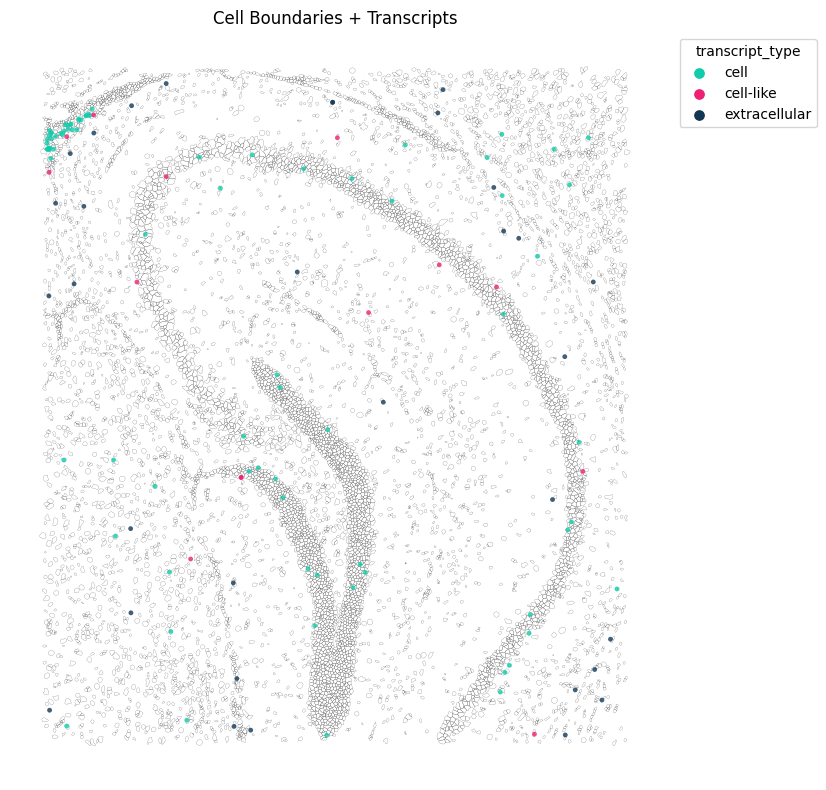

In [294]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Clic3'],scatter_size=12,boundary_linewidth=0.1)

No transformation matrix found. Proceeding without transformation.


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

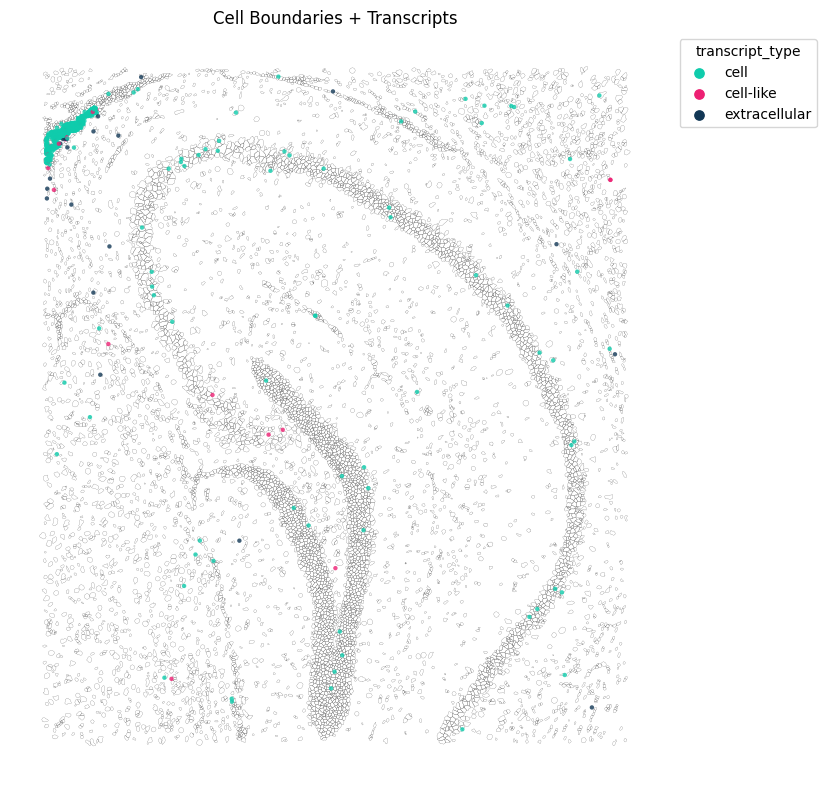

In [295]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Cldn2'],scatter_size=10,boundary_linewidth=0.1)

No transformation matrix found. Proceeding without transformation.


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

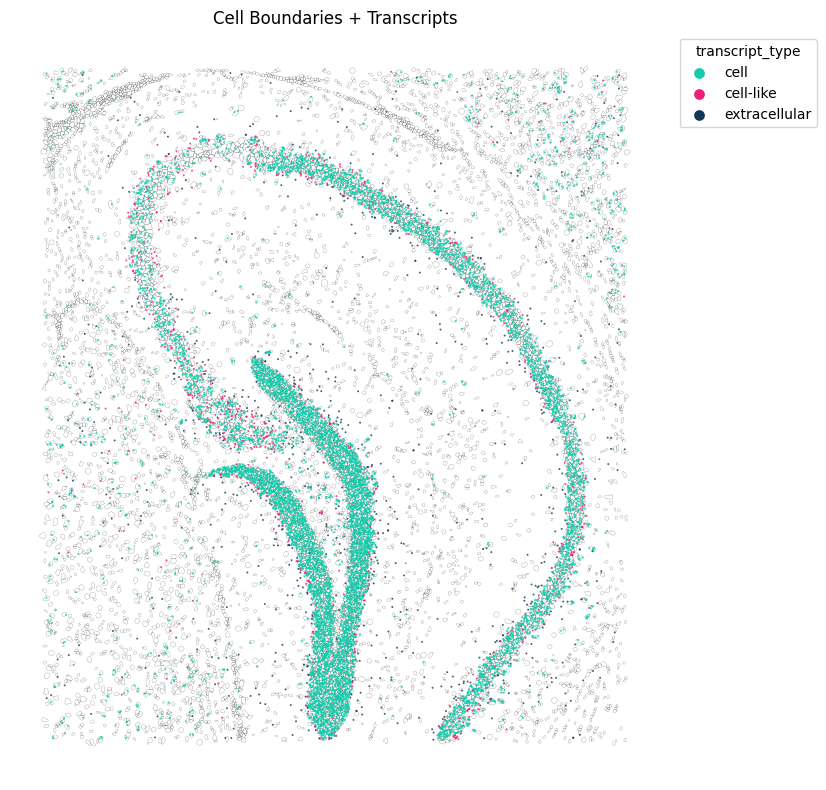

In [189]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Epha7'],scatter_size=2,boundary_linewidth=0.1)

No transformation matrix found. Proceeding without transformation.


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

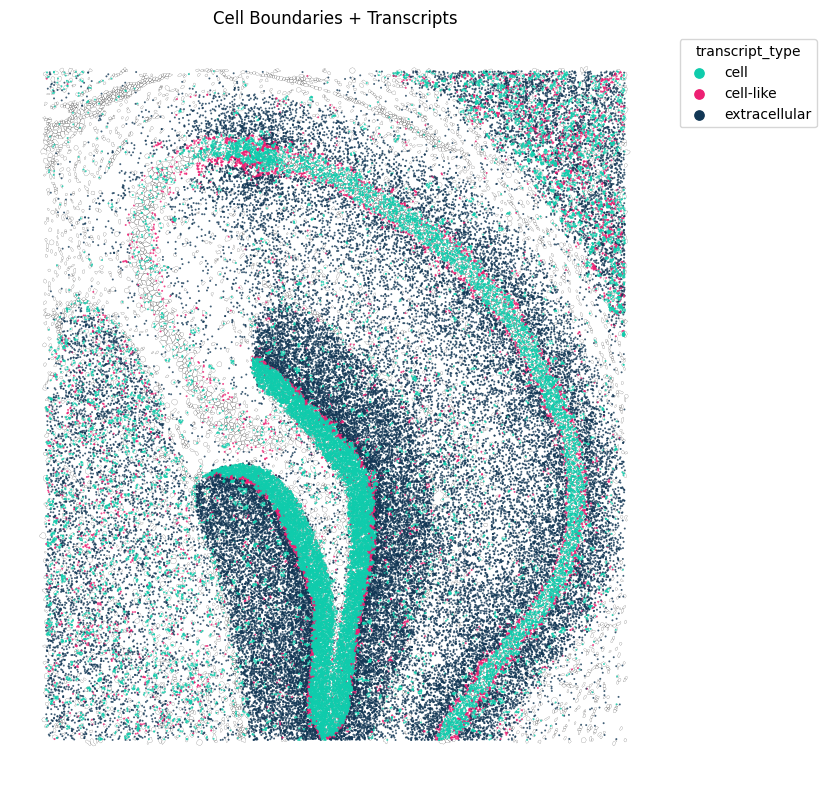

In [190]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Adcy1'],scatter_size=2,boundary_linewidth=0.1)

No transformation matrix found. Proceeding without transformation.


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

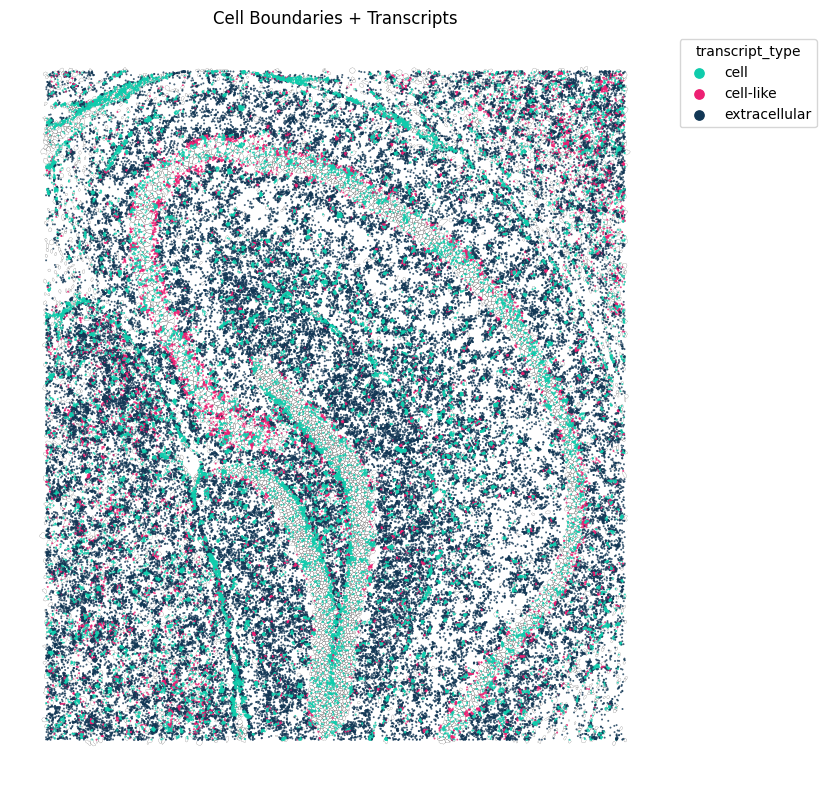

In [183]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Aldoc'],scatter_size=2,boundary_linewidth=0.1)

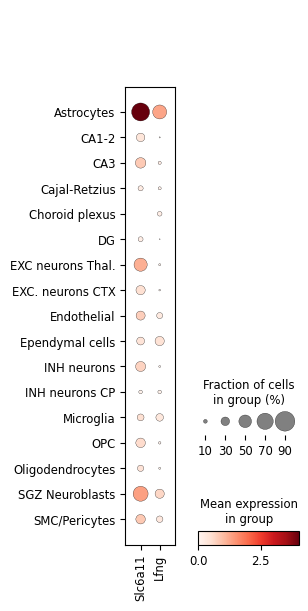

In [260]:
sc.pl.dotplot(adata,['Slc6a11','Lfng'],groupby='cell_type',layer='raw')

No transformation matrix found. Proceeding without transformation.


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

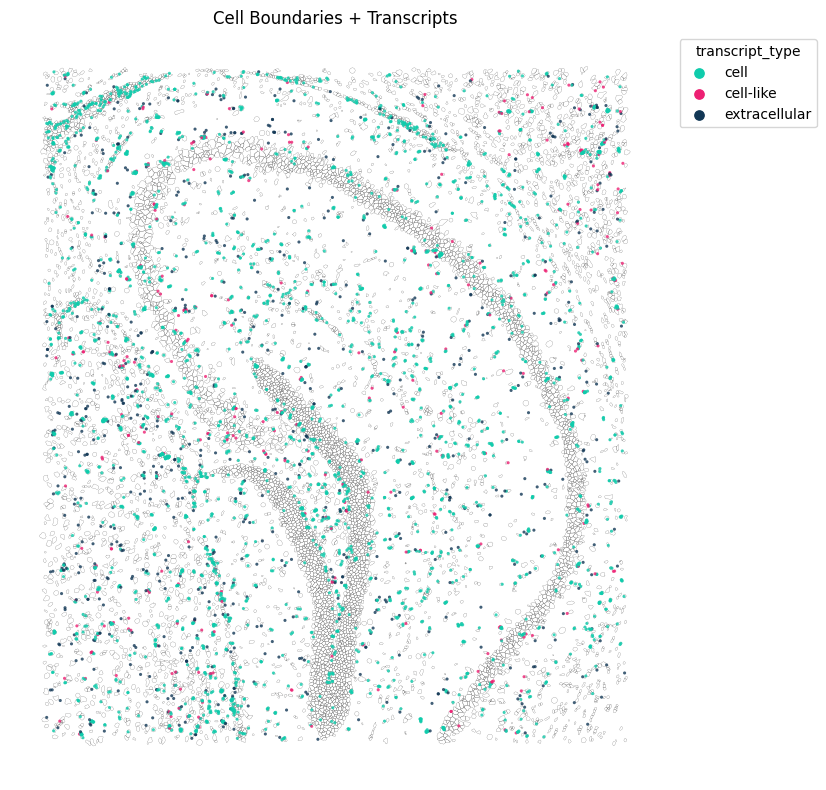

In [184]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Lfng'],scatter_size=5,boundary_linewidth=0.1)

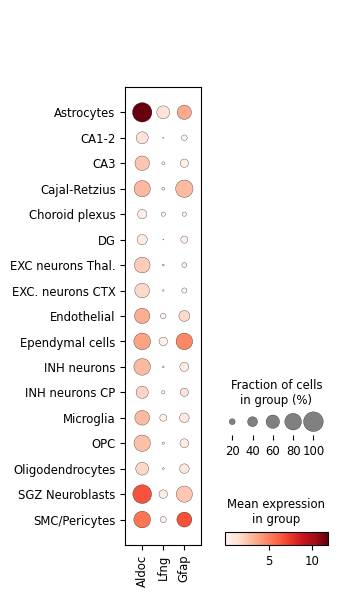

In [188]:
sc.pl.dotplot(adata,['Aldoc','Lfng','Gfap'],groupby='cell_type',layer='raw')

No transformation matrix found. Proceeding without transformation.


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

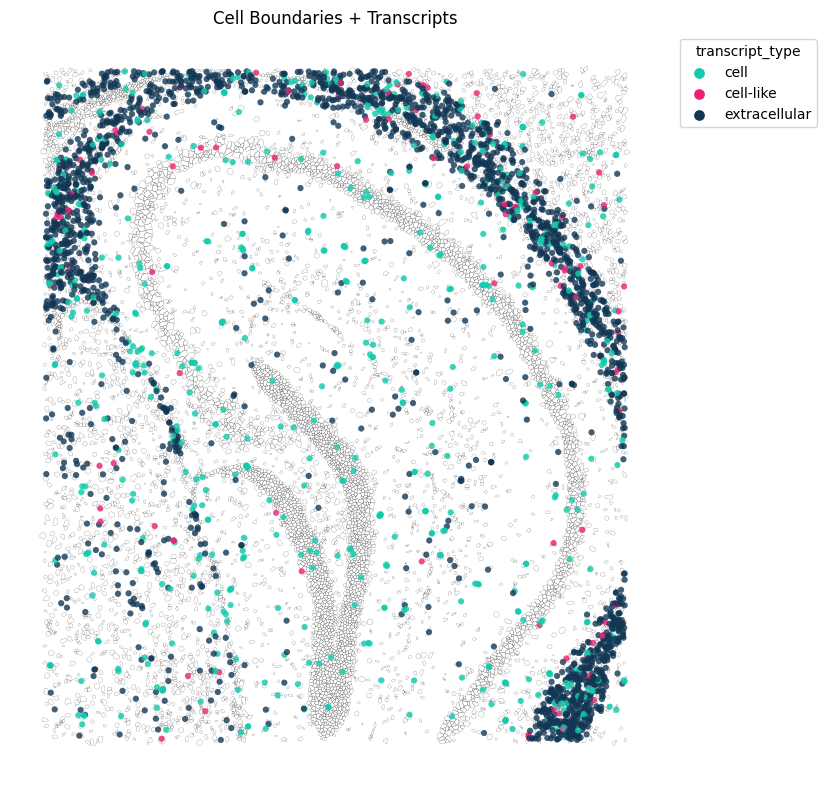

In [27]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Tmem173'],scatter_size=20,boundary_linewidth=0.1)

No transformation matrix found. Proceeding without transformation.


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

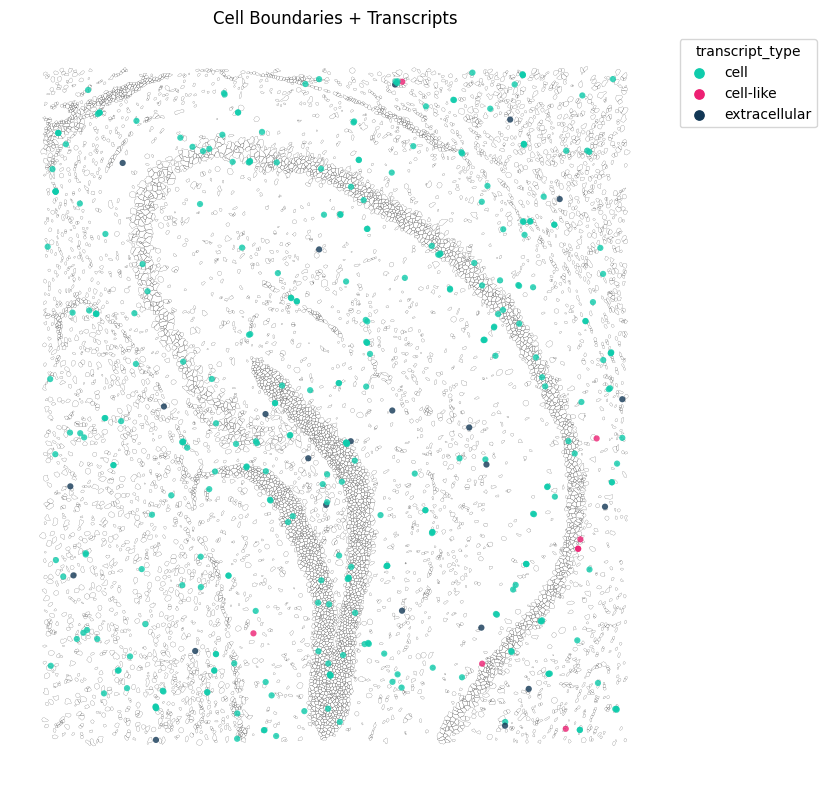

In [28]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Cd37'],scatter_size=20,boundary_linewidth=0.1)

No transformation matrix found. Proceeding without transformation.


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

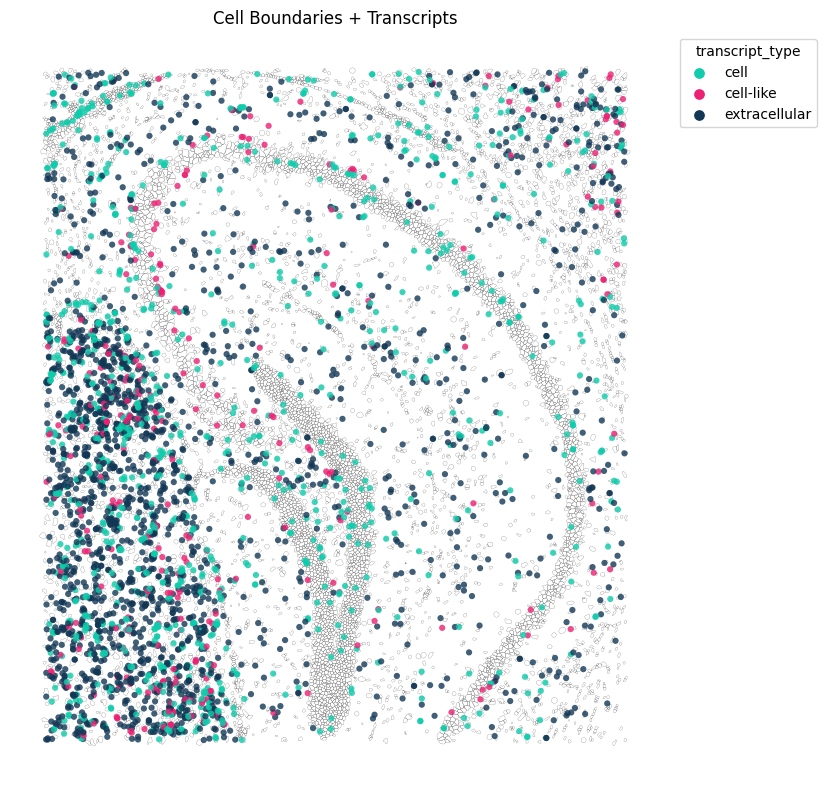

In [29]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Etnppl'],scatter_size=20,boundary_linewidth=0.1)

No transformation matrix found. Proceeding without transformation.


(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

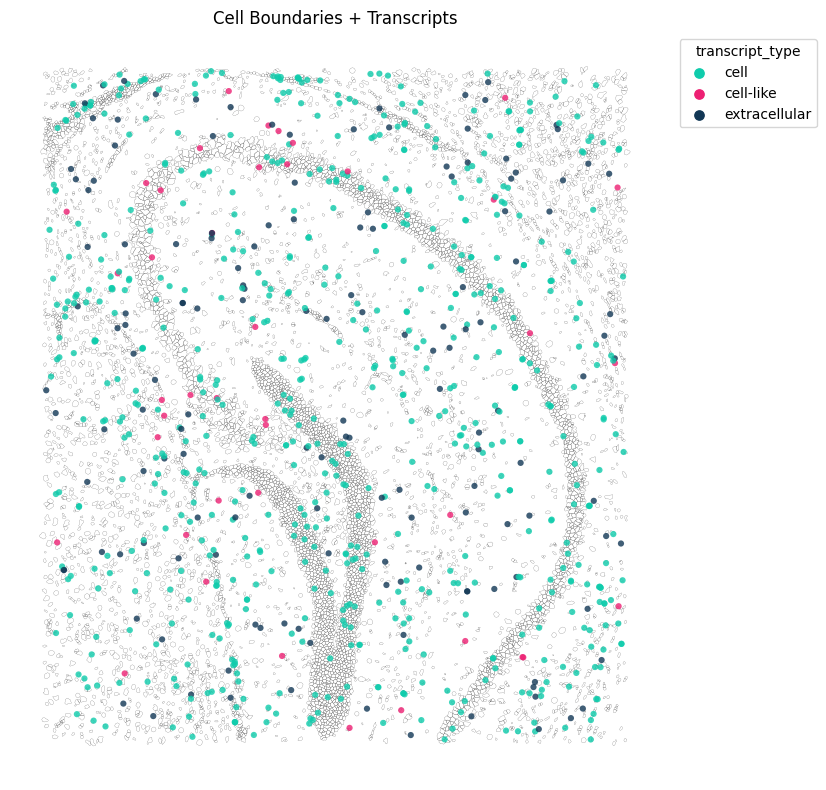

In [30]:
troutpy.pl.spatial_transcripts(sdata,gene_list=['Hif3a'],scatter_size=20,boundary_linewidth=0.1)

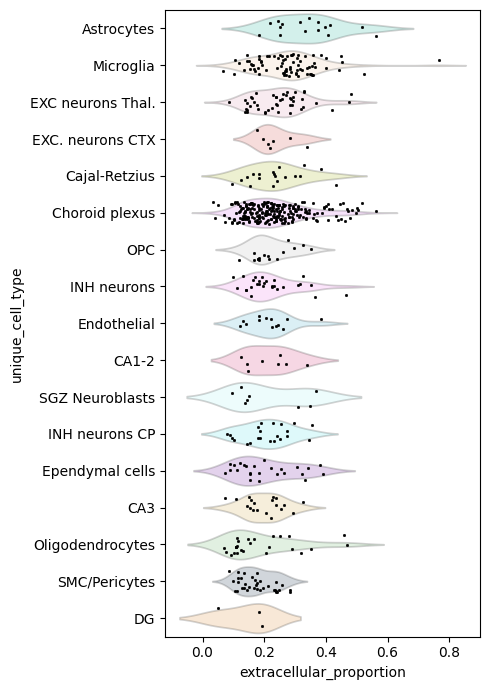

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Parameters
m = 2
n = 2

# Prepare data
merged_labelled = merged.copy()
merged_labelled['gene_name'] = merged_labelled.index

# Create safe order_ct lookup
y_map = {ct: i for i, ct in enumerate(order_ct)}

# Filter to only valid cell types
valid_ct = [ct for ct in merged_labelled['unique_cell_type'].unique() if ct in order_ct]

# Select top and bottom genes
to_label = []
for ct in valid_ct:
    group = merged_labelled[merged_labelled['unique_cell_type'] == ct]
    top_m = group.nlargest(m, 'extracellular_proportion')
    bottom_n = group.nsmallest(n, 'extracellular_proportion')
    to_label.append(pd.concat([top_m, bottom_n]))

label_df = pd.concat(to_label)

# Plot
plt.figure(figsize=(5, 7), dpi=100)

sns.violinplot(
    data=merged_labelled,
    y='unique_cell_type',
    x='extracellular_proportion',
    order=order_ct,
    palette=cols,
    alpha=0.2,
    inner=None
)

sns.stripplot(
    data=merged_labelled,
    y='unique_cell_type',
    x='extracellular_proportion',
    color='black',
    s=2,
    order=order_ct,
    jitter=0.3,
    linewidth=0.2
)

plt.tight_layout()
plt.show()


In [19]:
import matplotlib.pyplot as plt

def plot_scatter_with_labels(group, figsize=(8, 6), label_fontsize=8,title='Gene-level Scatter Plot with Labels'):
    """
    Plot a scatter plot of logfoldratio_over_noise vs. extracellular_proportion
    and annotate each point with the index (e.g., gene name).

    Parameters
    ----------
    group : pd.DataFrame
        DataFrame with 'logfoldratio_over_noise' and 'extracellular_proportion' columns,
        and labels (e.g., gene names) as the index.
    figsize : tuple
        Size of the figure.
    label_fontsize : int
        Font size of the text labels.
    """
    plt.figure(figsize=figsize)
    plt.scatter(group['logfoldratio_over_noise'], group['extracellular_proportion'], s=30, alpha=0.7)
    plt.xlabel('logfoldratio_over_noise')
    plt.ylabel('extracellular_proportion')
    plt.title(title)

    # Add text labels
    for name, row in group.iterrows():
        plt.text(row['logfoldratio_over_noise'], row['extracellular_proportion'], name,
                 fontsize=label_fontsize, ha='right', va='bottom')

    plt.grid(False)
    plt.tight_layout()
    plt.show()


Astrocytes


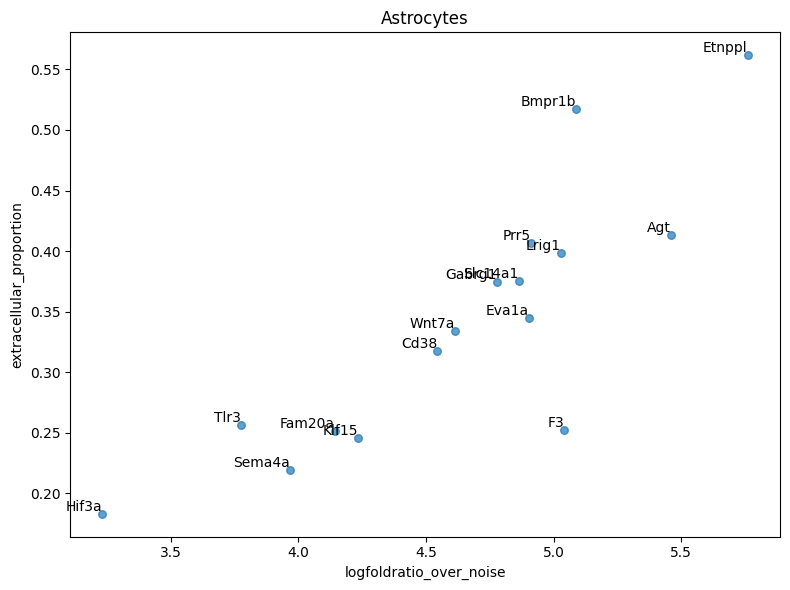

CA1-2


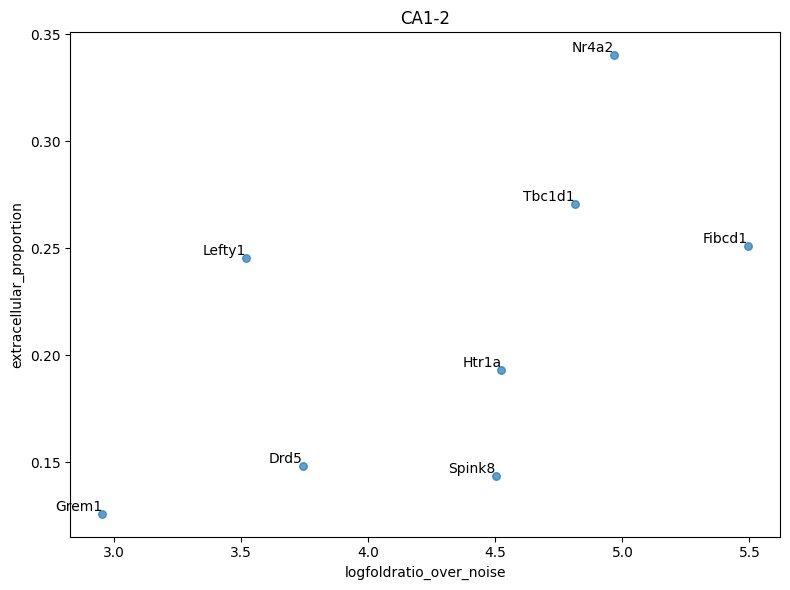

CA3


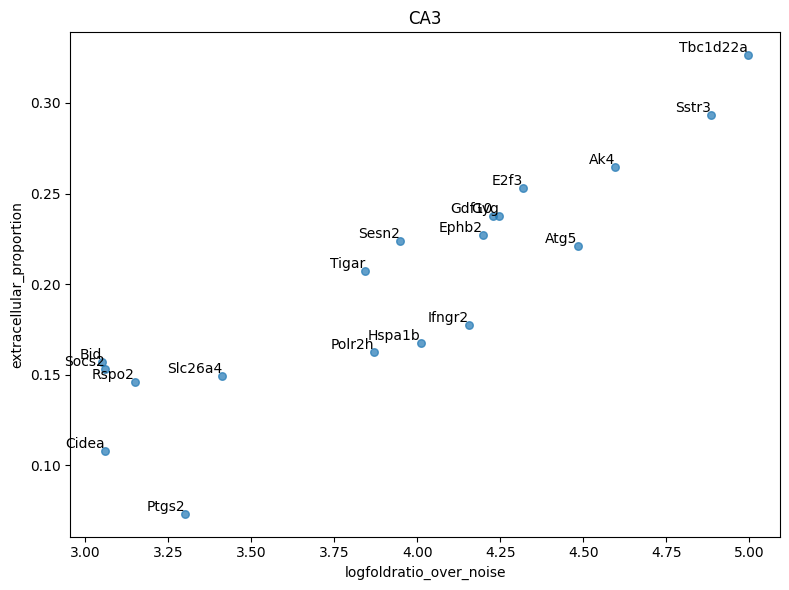

Cajal-Retzius


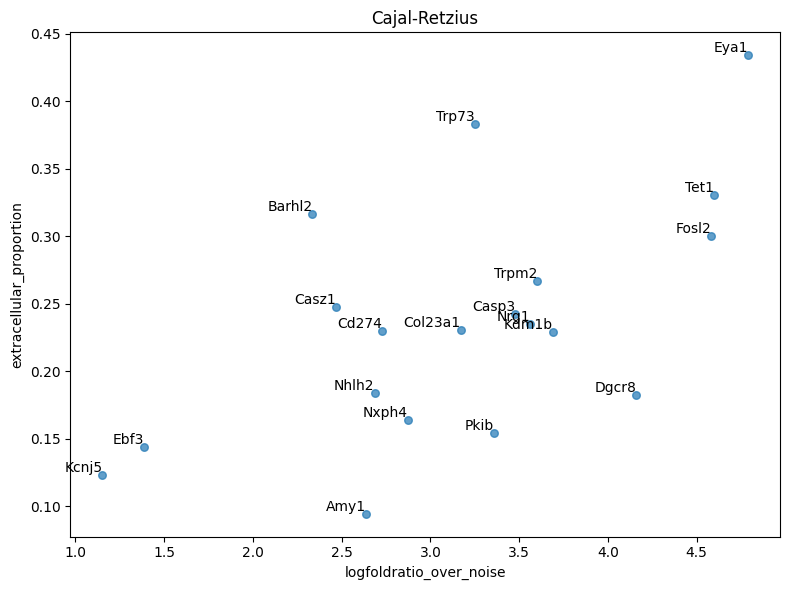

Choroid plexus


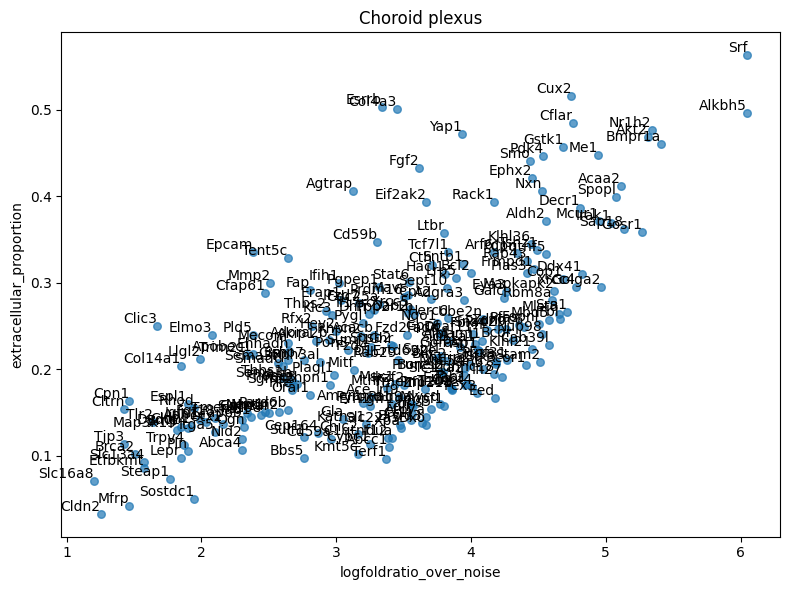

DG


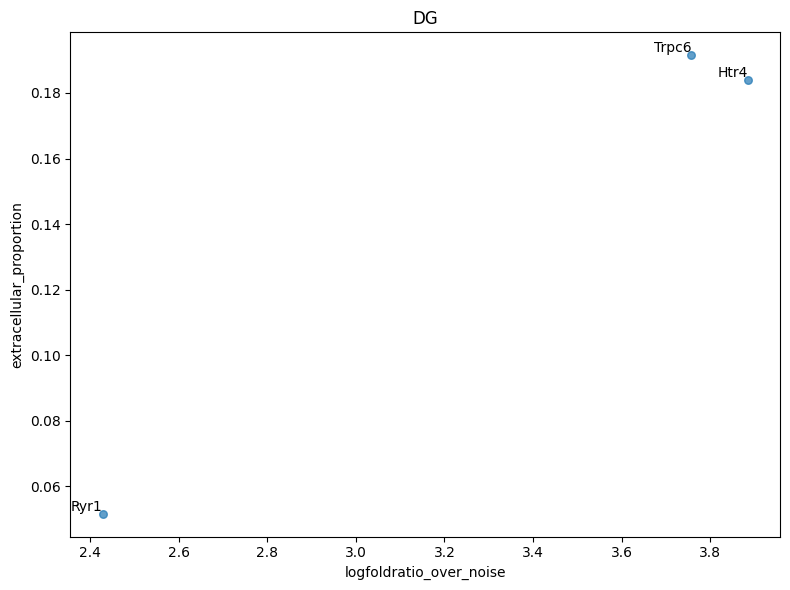

EXC neurons Thal.


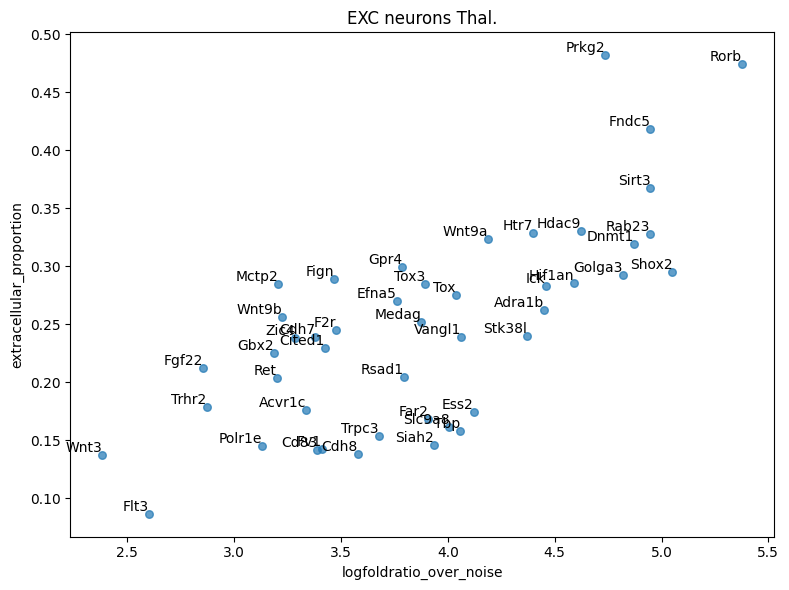

EXC. neurons CTX


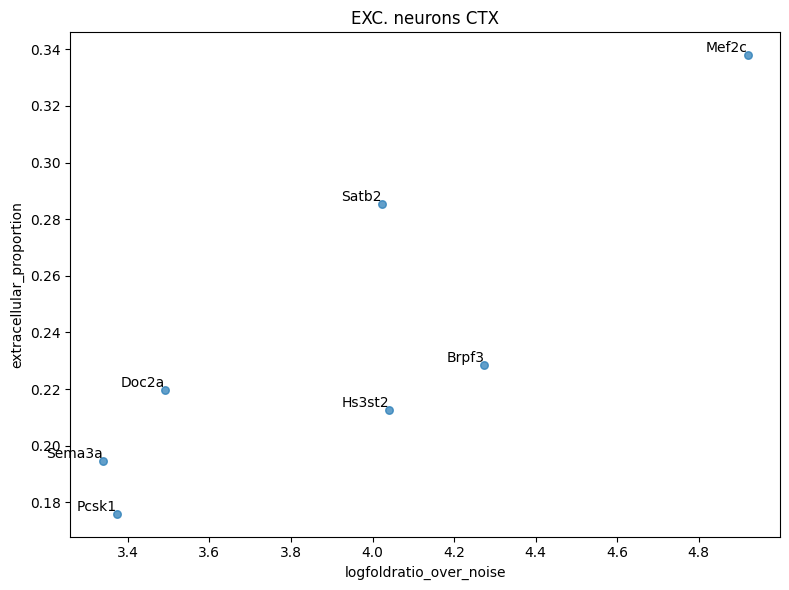

Endothelial


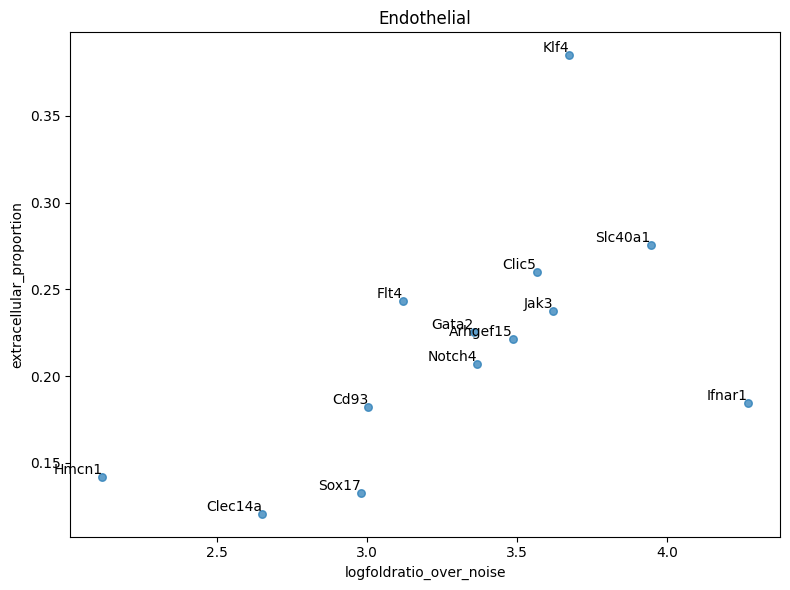

Ependymal cells


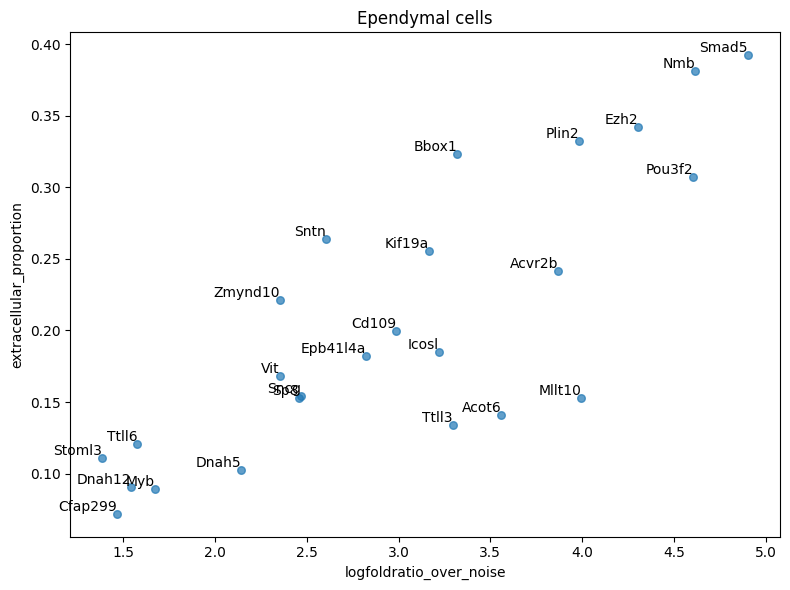

INH neurons


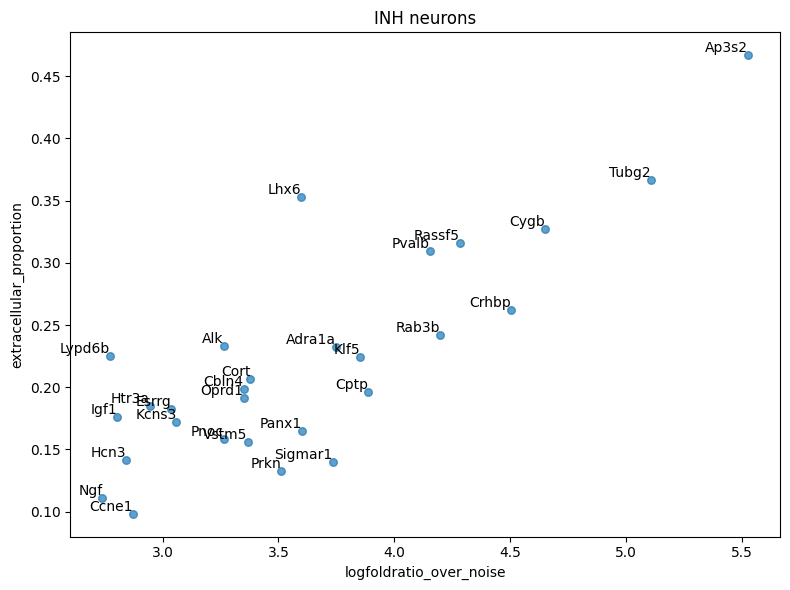

INH neurons CP


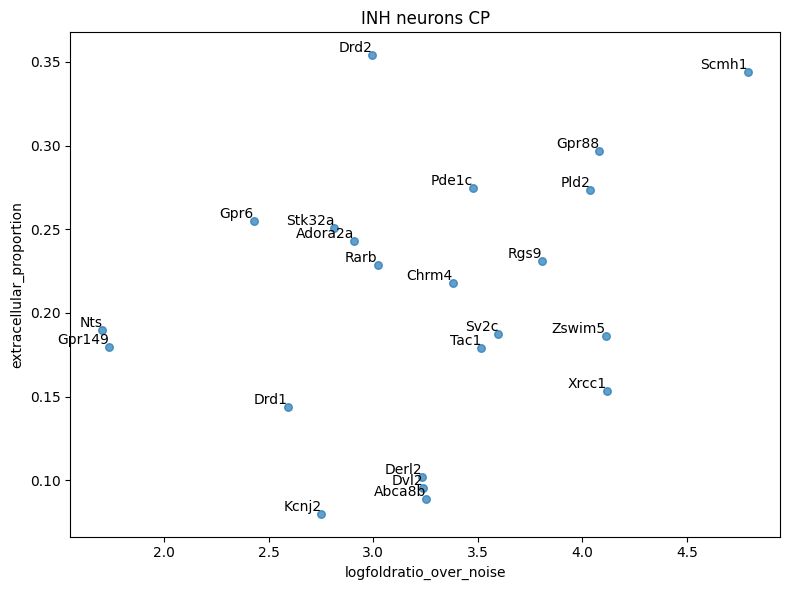

Microglia


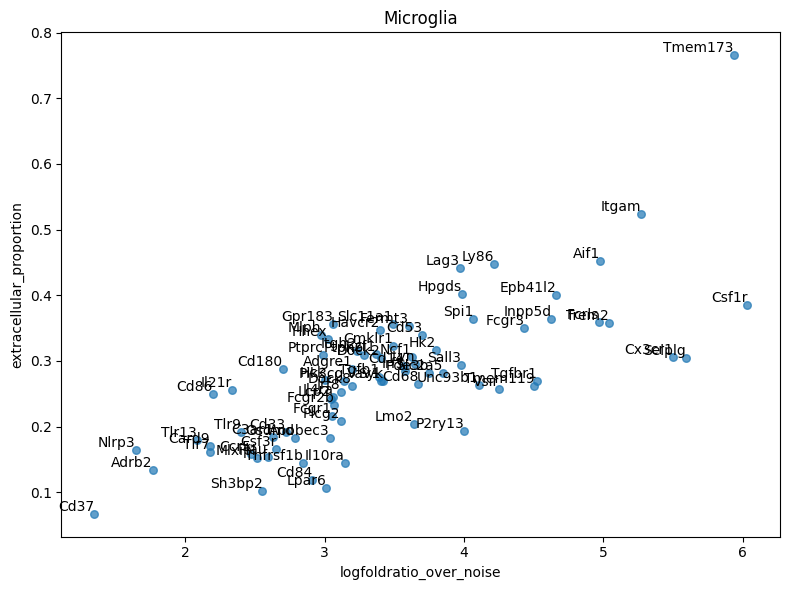

OPC


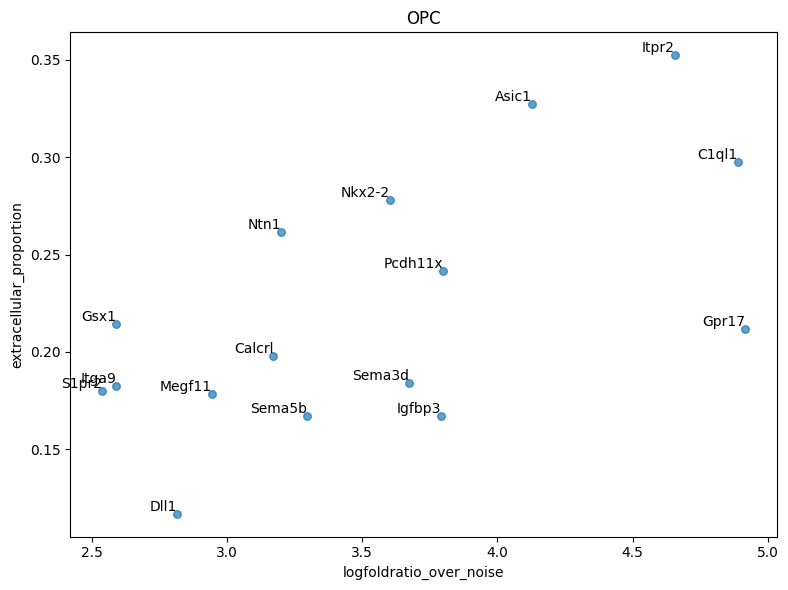

Oligodendrocytes


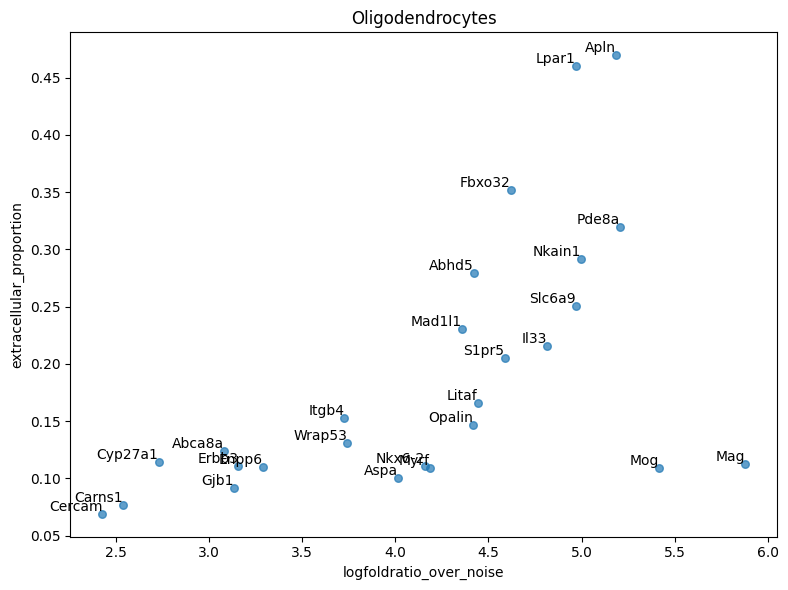

SGZ Neuroblasts


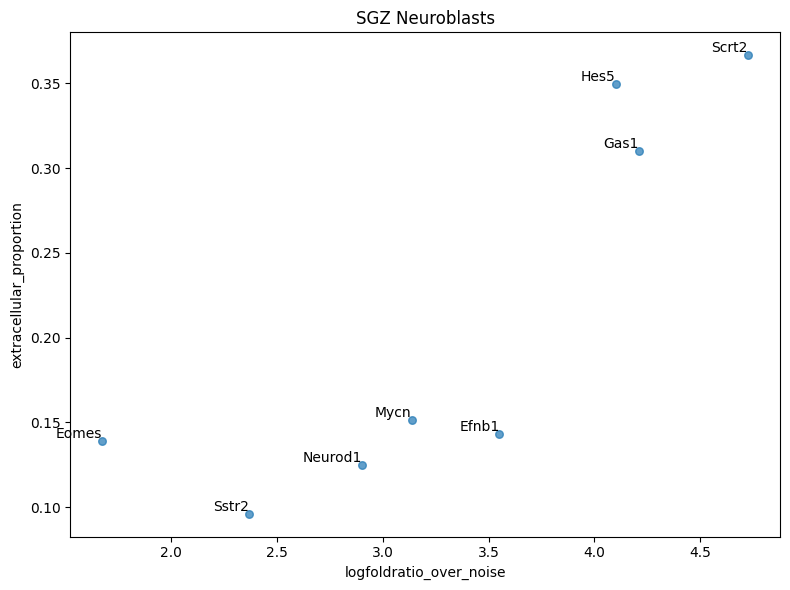

SMC/Pericytes


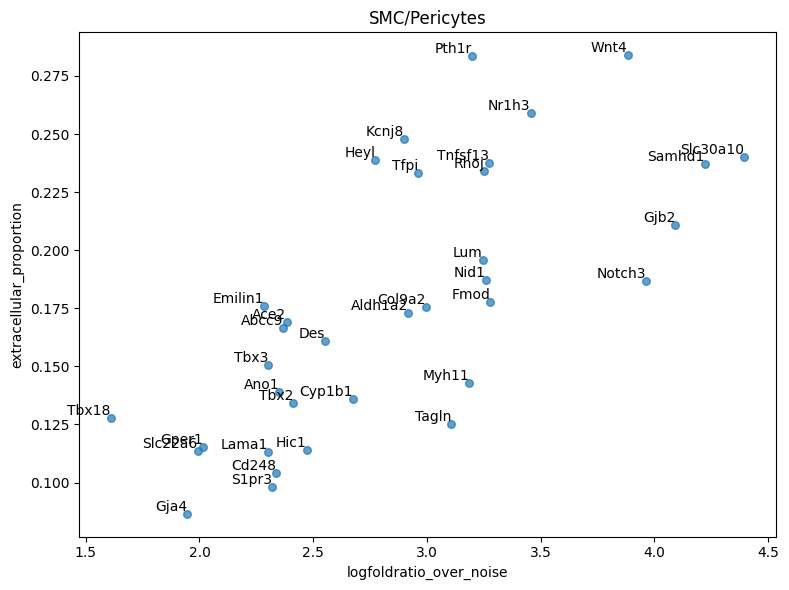

In [21]:
for ct,group in merged.groupby('unique_cell_type'):
    print(ct)
    plot_scatter_with_labels(group, figsize=(8, 6), label_fontsize=10,title=ct)

# Module analysis

In [ ]:
hs = hotspot.Hotspot(adata, layer_key="raw", model="danb", latent_obsm_key="X_pca", umi_counts_obs_key="n_counts")

hs.create_knn_graph(weighted_graph=False, n_neighbors=10)
hs_results = hs.compute_autocorrelations()
hs_genes = hs_results.loc[hs_results.FDR < 0.005].index  # Select genes
local_correlations = hs.compute_local_correlations(hs_genes, jobs=4)  # jobs for parallelization

In [ ]:
# calculate modules
modules = hs.create_modules(min_gene_threshold=10, core_only=True, fdr_threshold=0.0005)
module_scores = hs.calculate_module_scores()

In [ ]:
hs.plot_local_correlations(vmax=50, vmin=-50)

In [ ]:
adata_scores = sc.AnnData(module_scores, obs=adata.obs)
adata_scores.obsm["X_umap"] = adata.obsm["X_umap"]
adata_scores.obsm["X_pca"] = adata.obsm["X_pca"]
sc.pl.umap(adata, color="leiden")
sc.pl.umap(adata_scores, color=adata_scores.var.index, vmax="p99")

In [ ]:
dictmod = dict(zip(modules.index, modules.values))
results=sdata['xrna_metadata'].var
results["module"] = results.index.map(dictmod)

In [ ]:
import matplotlib.pyplot as plt


def annotate_top_bottom(
    df, metric1, metric2, n=5, label_col=None, figsize=(8, 6), scatter_kwargs=None, annotate_kwargs=None, title_tag=""
):
    """
    Scatter-plot df[metric1] vs df[metric2] and annotate the top/bottom n points
    along each axis.

    Parameters
    ----------
    df : pandas.DataFrame
        The data.
    metric1 : str
        Column name for the x-axis metric.
    metric2 : str
        Column name for the y-axis metric.
    n : int, optional (default=5)
        Number of top and bottom points to label per metric.
    label_col : str or None, optional (default=None)
        Column name containing the labels. If None, uses df.index.
    figsize : tuple, optional (default=(8, 6))
        Figure size.
    scatter_kwargs : dict or None
        Extra kwargs passed to plt.scatter().
    annotate_kwargs : dict or None
        Extra kwargs passed to plt.annotate().
    Title tag: str, optional (default='')

    Returns
    -------
    fig, ax : matplotlib.figure.Figure, matplotlib.axes.Axes
        The figure and axes objects.
    """
    # Prepare labels
    df_plot = df.copy()
    if label_col is None:
        df_plot["__idx_label"] = df_plot.index.astype(str)
        label_col = "__idx_label"

    # Plot
    fig, ax = plt.subplots(figsize=figsize)
    sc_kwargs = {} if scatter_kwargs is None else scatter_kwargs
    ax.scatter(df_plot[metric1], df_plot[metric2], **sc_kwargs)
    ax.set_xlabel(metric1)
    ax.set_ylabel(metric2)
    ax.set_title(f"{title_tag}: {metric1} vs {metric2}")

    # Find indices to annotate
    top1 = df_plot.nlargest(n, metric1).index
    bot1 = df_plot.nsmallest(n, metric1).index
    top2 = df_plot.nlargest(n, metric2).index
    bot2 = df_plot.nsmallest(n, metric2).index
    to_annotate = set(top1) | set(bot1) | set(top2) | set(bot2)

    # Annotate
    ann_kwargs = dict(xytext=(5, 5), textcoords="offset points", ha="left", va="bottom", fontsize=8, alpha=0.8)
    if annotate_kwargs:
        ann_kwargs.update(annotate_kwargs)

    for idx in to_annotate:
        x = df_plot.loc[idx, metric1]
        y = df_plot.loc[idx, metric2]
        label = df_plot.loc[idx, label_col]
        ax.annotate(label, xy=(x, y), **ann_kwargs)

    fig.tight_layout()
    return fig, ax

In [ ]:
results2 = results[results["logfoldratio_over_noise"] > 0]
fig, ax = annotate_top_bottom(
    df=results2,
    metric1="logfoldratio_over_noise",
    metric2="in_out_spearmanR",
    n=10,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    figsize=(7, 7),
)
plt.show()

In [ ]:
fig, ax = annotate_top_bottom(
    df=results2,
    metric1="logfoldratio_over_noise",
    metric2="extracellular_proportion",
    n=50,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    figsize=(7, 7),
)
plt.show()

In [ ]:
# spatial maps-in out
g2 = "Gap43"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10)

In [ ]:
for g, i in results.groupby("module"):
    if g > -1:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="extracellular_proportion",
            n=5,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 9, "color": "black"},
            title_tag=g,
            figsize=(4, 4),
        )
        plt.show()

In [ ]:
for g, i in results.groupby("module"):
    if g > -1:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="in_out_spearmanR",
            n=5,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 9, "color": "black"},
            title_tag=g,
            figsize=(4, 4),
        )
        plt.show()

In [ ]:
import pandas as pd

mods_df = pd.DataFrame(modules).sort_values(by="Module")
genes = mods_df[mods_df["Module"] == 1].index
sc.pl.umap(adata, color=genes, vmax="p99")
print(genes)

In [ ]:
g2 = "CAVIN2"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=40, spot_size_extra=40)

In [ ]:
g2 = "FABP4"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=40, spot_size_extra=40)

In [ ]:
merged_info.sort_values(by=[metric + "_cosmx"], ascending=False)

In [ ]:
fig, ax = annotate_top_bottom(
    df=results,
    metric1="logfoldratio_over_noise",
    metric2="extracellular_proportion",
    n=5,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    title_tag=g,
    figsize=(4, 4),
)
plt.show()

In [ ]:
g2 = "FZD4"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10, spot_size_extra=10)

In [ ]:
trans = sdata["transcripts"].compute()

In [ ]:
trans["segstatus"] = trans["overlaps_cell"].astype(str) + "_" + trans["extracellular"].astype(str)
stat2lab = {"True_False": "cell", "False_True": "extracellular", "False_False": "cell-like"}

In [ ]:
trans["type"] = trans["segstatus"].map(stat2lab)

In [ ]:
trans2 = trans.loc[:, ["x", "y", "gene", "type"]]

In [ ]:
trans2.to_csv("/media/sergio/Meninges/trans2.csv")